--- Allocation Optimale des Actifs ---
     Portefeuille Max Sharpe Portefeuille Min Variance
AAPL                  41.13%                     0.00%
MSFT                   0.00%                     0.00%
NVDA                  50.45%                     0.00%
SPY                    0.00%                    94.66%
JPM                    0.00%                     0.00%
XOM                    8.43%                     5.34%


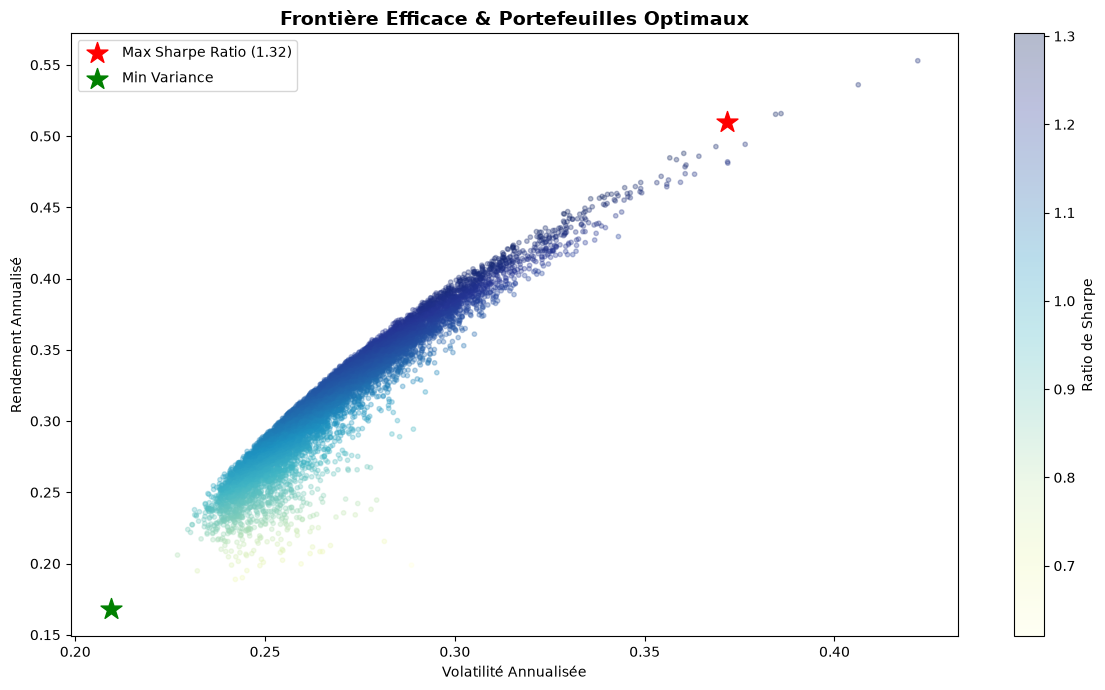

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from marketlens.portfolio import (
    optimize_minimum_variance,
    optimize_sharpe_ratio,
)
from marketlens.returns import calculate_simple_returns

# 1. Charger les données de prix nettoyées
prices = pd.read_csv(
    "../data/processed/cleaned_prices.csv", index_col=0, parse_dates=True
)
daily_returns = calculate_simple_returns(prices)

# Calcul des rendements moyens quotidiens et de la matrice de covariance
mean_returns = daily_returns.mean()
cov_matrix = daily_returns.cov()

# 2. Optimisation des portefeuilles (SLSQP)
max_sharpe_weights, max_sharpe_stats = optimize_sharpe_ratio(
    mean_returns, cov_matrix
)
min_vol_weights, min_vol_stats = optimize_minimum_variance(
    mean_returns, cov_matrix
)

# Affichage des poids optimaux
weights_df = pd.DataFrame(
    {
        "Portefeuille Max Sharpe": max_sharpe_weights,
        "Portefeuille Min Variance": min_vol_weights,
    },
    index=prices.columns,
)

print("--- Allocation Optimale des Actifs ---")
print(weights_df.map(lambda x: f"{x:.2%}"))

# 3. Simulation Monte Carlo Ultra-Rapide (Vectorisée)
num_portfolios = 10000
num_assets = len(prices.columns)
np.random.seed(42)

# Génération matricielle des poids
weights_matrix = np.random.random((num_portfolios, num_assets))
weights_matrix /= weights_matrix.sum(axis=1)[:, np.newaxis]

# Annualisation des paramètres
ann_mean_returns = mean_returns.values * 252
ann_cov_matrix = cov_matrix.values * 252

# Calculs vectorisés en C/NumPy (prend < 0.1s)
portfolio_returns = np.dot(weights_matrix, ann_mean_returns)
portfolio_volatilities = np.sqrt(
    np.einsum(
        "ij,ji->i",
        np.dot(weights_matrix, ann_cov_matrix),
        weights_matrix.T,
    )
)
sharpe_ratios = (portfolio_returns - 0.02) / portfolio_volatilities

# 4. Visualisation de la Frontière Efficace
plt.figure(figsize=(12, 7))
plt.scatter(
    portfolio_volatilities,
    portfolio_returns,
    c=sharpe_ratios,
    cmap="YlGnBu",
    marker="o",
    s=10,
    alpha=0.3,
)
plt.colorbar(label="Ratio de Sharpe")

# Marquer le portefeuille Max Sharpe
plt.scatter(
    max_sharpe_stats["Volatility"],
    max_sharpe_stats["Return"],
    marker="*",
    color="r",
    s=250,
    label=f"Max Sharpe Ratio ({max_sharpe_stats['Sharpe Ratio']:.2f})",
)

# Marquer le portefeuille Variance Minimale
plt.scatter(
    min_vol_stats["Volatility"],
    min_vol_stats["Return"],
    marker="*",
    color="g",
    s=250,
    label="Min Variance",
)

plt.title(
    "Frontière Efficace & Portefeuilles Optimaux",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Volatilité Annualisée")
plt.ylabel("Rendement Annualisé")
plt.legend(labelspacing=0.8)
plt.tight_layout()

# Sauvegarde de la figure
plt.savefig("../reports/figures/05_efficient_frontier.png")
plt.show()